In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [4]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [5]:
len(words)

32033

In [20]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = { s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = { s: i for i, s in stoi.items()}
stoi

{'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26,
 '.': 0}

In [96]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []

for w in words:
    # print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix] # crop and append
X = torch.tensor(X)
Y = torch.tensor(Y)
        

In [97]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [27]:
C = torch.randn((27, 2))


In [28]:
C[5]

tensor([0.5466, 0.3078])

In [32]:
F.one_hot((torch.tensor(5)), num_classes=27).float() @ C


tensor([0.5466, 0.3078])

In [43]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [42]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [48]:
torch.cat([emb [:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

torch.Size([32, 6])

In [52]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([32, 6])

In [57]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h

tensor([[ 0.9551,  0.9948,  0.6679,  ..., -0.1881,  0.9996, -0.9888],
        [ 0.7432,  0.9616,  0.7808,  ..., -0.3149,  0.9981, -0.9544],
        [ 0.9993,  0.9803, -0.6350,  ...,  0.3395,  0.9993, -0.6673],
        ...,
        [-0.8720, -0.7487,  0.9821,  ..., -0.5328, -0.3596, -0.8128],
        [ 0.9876, -1.0000, -0.1614,  ..., -0.4150, -0.9992,  0.9991],
        [ 0.9839, -0.5447,  0.2900,  ..., -0.5827,  0.7704, -0.4136]])

In [58]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [60]:
logits = h @ W2 + b2

In [ ]:
logits.shape

In [63]:
counts = logits.exp()

In [65]:
prob = counts / counts.sum(1, keepdims=True)

In [66]:
prob.shape

torch.Size([32, 27])

In [67]:
prob[0].sum()

tensor(1.0000)

In [73]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(15.2336)

In [74]:
# better writing

In [102]:
X. shape, Y.shape # dataset

(torch.Size([228146, 3]), torch.Size([228146]))

In [180]:
g = torch.Generator().manual_seed(2147483647)
c = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [181]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [182]:
for p in parameters:
    p.requires_grad = True

In [183]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [235]:
lri = []
lossi = []

for i in range(10000):
    # minibatch construct
    ix = torch.randint(0, X.shape[0], (128,))
    
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
    logits = h @ W2 + b2 # (32, 27)
    # counts = logits.exp()
    # prob = counts / counts.sum(1, keepdims=True)
    # loss = -prob[torch.arange(32), Y].log().mean()
    loss = F.cross_entropy(logits, Y[ix])
    # print(loss.item())
    
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    
    # update
    # lr = lrs[i]
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    # lri.append(lr)
    # lossi.append(loss.item())
    

In [236]:
emb = C[X] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Y)
loss

tensor(2.4343, grad_fn=<NllLossBackward0>)

In [ ]:
plt.plot(lri, lossi)

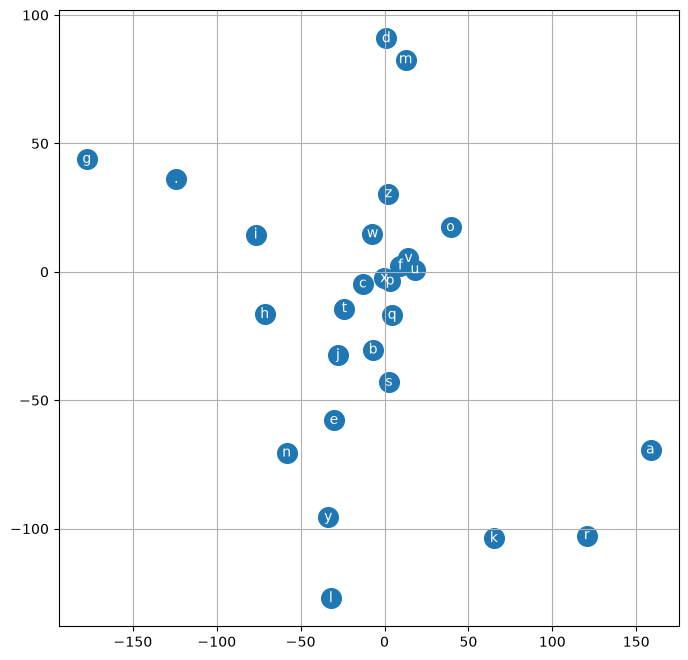

In [237]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range (C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')